In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

In [ ]:
import kagglehub
import shutil

# Descargar
path = kagglehub.competition_download("filament-segmentation-2026")

# Copiar a /content
destino = "/content/filament-segmentation-2026"

shutil.copytree(path, destino, dirs_exist_ok=True)

print(destino)

100%|██████████| 671M/671M [00:05<00:00, 122MB/s]

Extracting files...


/content/filament-segmentation-2026


In [ ]:
import os
import json
import cv2
import numpy as np

# =====================================================================
# CONFIGURACIÓN DE RUTAS (Modifica esto con las rutas de tu ordenador)
# =====================================================================
RUTA_JSON = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"  # Ruta de tu archivo .json real
CARPETA_IMAGENES = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images"      # Carpeta donde están todas las fotos
CARPETA_SALIDA = "/content/resultados_filamentos"   # Carpeta donde se guardará todo

# Color Verde Fosforito en formato BGR (OpenCV)
GREEN_LIME = (0, 255, 0)

def procesar_dataset_masivo():
    # 1. Validar que el archivo JSON exista
    if not os.path.exists(RUTA_JSON):
        print(f"❌ Error: No se encuentra el archivo JSON en '{RUTA_JSON}'")
        return

    # 2. Crear la carpeta de salida si no existe
    os.makedirs(CARPETA_SALIDA, exist_ok=True)

    # 3. Cargar el JSON en memoria
    print("⏳ Cargando archivo JSON masivo...")
    with open(RUTA_JSON, 'r', encoding='utf-8') as f:
        data = json.load(f)
    print("✅ JSON cargado correctamente.")

    # 4. Mapear metadatos de las imágenes por ID
    images_dict = {img['id']: img for img in data.get('images', [])}

    # 5. Agrupar TODAS las anotaciones por su ID de imagen correspondiente
    print("📦 Agrupando anotaciones por imagen...")
    annotations_por_imagen = {}
    for ann in data.get('annotations', []):
        img_id = ann['image_id']
        if img_id not in annotations_por_imagen:
            annotations_por_imagen[img_id] = []
        annotations_por_imagen[img_id].append(ann)

    total_imagenes = len(annotations_por_imagen)
    print(f"📌 Se detectaron {total_imagenes} imágenes con filamentos en el JSON.")
    print("-" * 70)

    # 6. Bucle principal de procesamiento masivo
    contador_exito = 0

    for i, (img_id, lista_anotaciones) in enumerate(annotations_por_imagen.items(), 1):
        if img_id not in images_dict:
            continue

        img_info = images_dict[img_id]
        nombre_archivo = img_info['file_name']
        ruta_imagen_local = os.path.join(CARPETA_IMAGENES, nombre_archivo)

        # Saltarse la imagen si no existe físicamente en la carpeta
        if not os.path.exists(ruta_imagen_local):
            # Imprime aviso cada tanto para no saturar la pantalla si faltan muchas
            if i % 50 == 0 or i == 1:
                print(f"⚠️ [{i}/{total_imagenes}] Archivo '{nombre_archivo}' no encontrado en carpeta. Saltando...")
            continue

        # Leer imagen
        img = cv2.imread(ruta_imagen_local)
        if img is None:
            print(f"❌ Real error leyendo la imagen: {nombre_archivo}")
            continue

        # Dibujar todos los filamentos que pertenezcan a esta foto actual
        for ann in lista_anotaciones:
            # Polígonos (Segmentation)
            if 'segmentation' in ann and ann['segmentation']:
                for seg in ann['segmentation']:
                    pts = np.array(seg, dtype=np.int32).reshape((-1, 1, 2))
                    cv2.polylines(img, [pts], isClosed=True, color=GREEN_LIME, thickness=3)

                    # Efecto translúcido verde
                    overlay = img.copy()
                    cv2.fillPoly(overlay, [pts], color=GREEN_LIME)
                    cv2.addWeighted(overlay, 0.3, img, 0.7, 0, img)

            # Cajas (si no hay polígono)
            elif 'bbox' in ann and ann['bbox']:
                x, y, w, h = map(int, ann['bbox'])
                cv2.rectangle(img, (x, y), (x + w, y + h), color=GREEN_LIME, thickness=3)

        # Guardar en la carpeta de destino
        ruta_salida_completa = os.path.join(CARPETA_SALIDA, f"analizada_{nombre_archivo}")
        cv2.imwrite(ruta_salida_completa, img)
        contador_exito += 1

        # Barra de progreso simple en consola cada 50 fotos
        if contador_exito % 50 == 0:
            print(f"📸 Progreso: {i}/{total_imagenes} imágenes evaluadas... ({contador_exito} procesadas con éxito)")

    print("-" * 70)
    print(f"🎉 ¡Proceso masivo terminado!")
    print(f"📂 Total de fotos guardadas con filamentos pintados: {contador_exito} en '{CARPETA_SALIDA}'")

if __name__ == "__main__":
    procesar_dataset_masivo()

⏳ Cargando archivo JSON masivo...
✅ JSON cargado correctamente.
📦 Agrupando anotaciones por imagen...
📌 Se detectaron 1154 imágenes con filamentos en el JSON.
----------------------------------------------------------------------
📸 Progreso: 50/1154 imágenes evaluadas... (50 procesadas con éxito)
📸 Progreso: 100/1154 imágenes evaluadas... (100 procesadas con éxito)
📸 Progreso: 150/1154 imágenes evaluadas... (150 procesadas con éxito)
📸 Progreso: 200/1154 imágenes evaluadas... (200 procesadas con éxito)
📸 Progreso: 250/1154 imágenes evaluadas... (250 procesadas con éxito)
📸 Progreso: 300/1154 imágenes evaluadas... (300 procesadas con éxito)
📸 Progreso: 350/1154 imágenes evaluadas... (350 procesadas con éxito)
📸 Progreso: 400/1154 imágenes evaluadas... (400 procesadas con éxito)
📸 Progreso: 450/1154 imágenes evaluadas... (450 procesadas con éxito)
📸 Progreso: 500/1154 imágenes evaluadas... (500 procesadas con éxito)
📸 Progreso: 550/1154 imágenes evaluadas... (550 procesadas con éxito)
📸 

In [ ]:
!zip -r /content/fotos_nuevas.zip /content/fotosnuevas

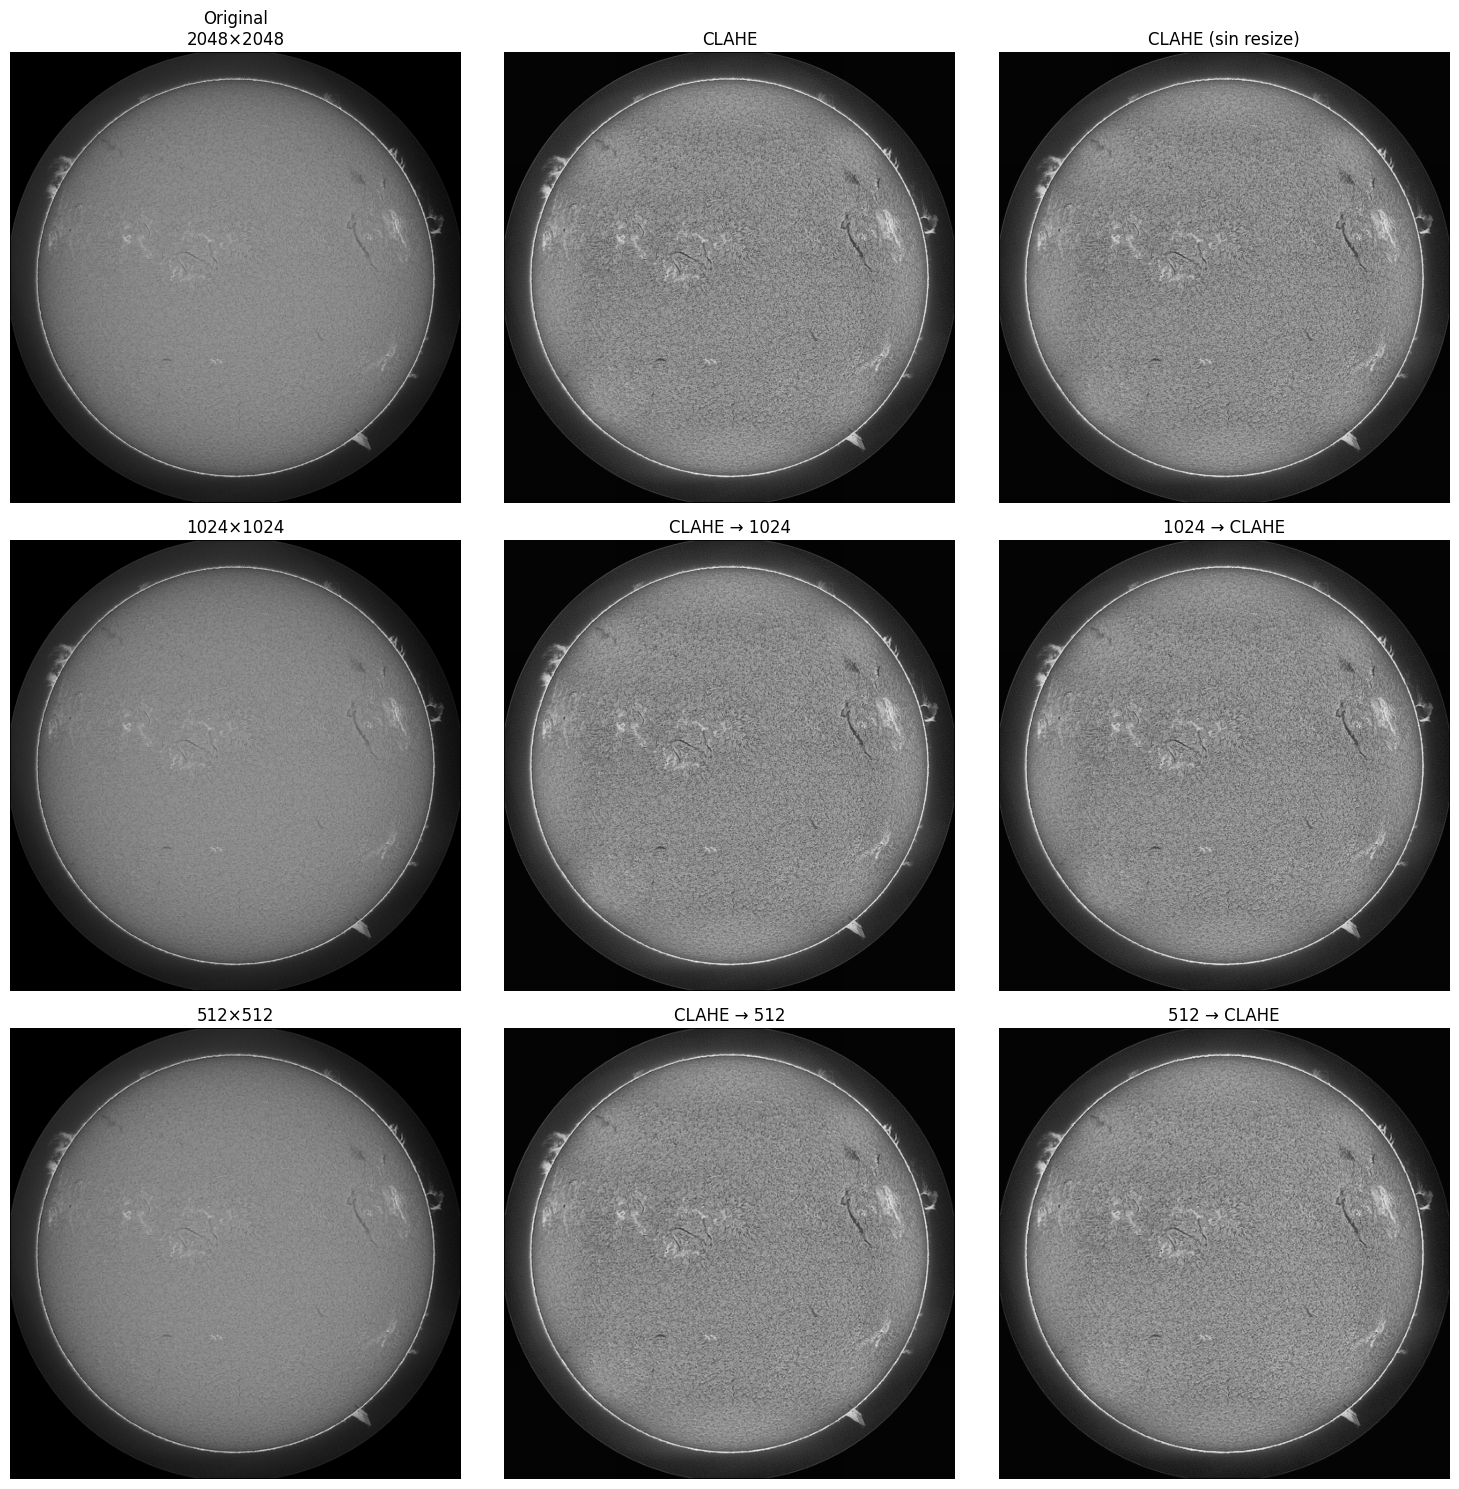

In [ ]:
# !pip install opencv-python pillow matplotlib

from PIL import Image
import matplotlib.pyplot as plt
import cv2
import numpy as np

# ==========================
# Función CLAHE para color
# ==========================
def aplicar_clahe_color(img_pil, clipLimit=2.0, tileGridSize=(8,8)):
    # PIL -> OpenCV
    img = np.array(img_pil)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    # BGR -> LAB
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    # CLAHE sobre la luminancia
    clahe = cv2.createCLAHE(
        clipLimit=clipLimit,
        tileGridSize=tileGridSize
    )
    l = clahe.apply(l)

    # Reconstrucción
    lab = cv2.merge((l, a, b))
    img = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    return Image.fromarray(img)

# ==========================
# Cargar imagen
# ==========================
img = Image.open("/content/20110826074214Th.jpeg").convert("RGB")

# ==========================
# Columna 1: Sin CLAHE
# ==========================
img_1024 = img.resize((1024,1024), Image.Resampling.LANCZOS)
img_512  = img.resize((512,512), Image.Resampling.LANCZOS)

# ==========================
# Columna 2: CLAHE -> Resize
# ==========================
clahe_original = aplicar_clahe_color(img)

clahe_resize_1024 = clahe_original.resize(
    (1024,1024), Image.Resampling.LANCZOS
)

clahe_resize_512 = clahe_original.resize(
    (512,512), Image.Resampling.LANCZOS
)

# ==========================
# Columna 3: Resize -> CLAHE
# ==========================
resize1024_clahe = aplicar_clahe_color(img_1024)
resize512_clahe  = aplicar_clahe_color(img_512)

# ==========================
# Mostrar resultados
# ==========================
fig, ax = plt.subplots(3,3, figsize=(15,15))

# Fila 1
ax[0,0].imshow(img)
ax[0,0].set_title(f"Original\n{img.size[0]}×{img.size[1]}")

ax[0,1].imshow(clahe_original)
ax[0,1].set_title("CLAHE")

ax[0,2].imshow(clahe_original)
ax[0,2].set_title("CLAHE (sin resize)")

# Fila 2
ax[1,0].imshow(img_1024)
ax[1,0].set_title("1024×1024")

ax[1,1].imshow(clahe_resize_1024)
ax[1,1].set_title("CLAHE → 1024")

ax[1,2].imshow(resize1024_clahe)
ax[1,2].set_title("1024 → CLAHE")

# Fila 3
ax[2,0].imshow(img_512)
ax[2,0].set_title("512×512")

ax[2,1].imshow(clahe_resize_512)
ax[2,1].set_title("CLAHE → 512")

ax[2,2].imshow(resize512_clahe)
ax[2,2].set_title("512 → CLAHE")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()

Imágenes: 1154
Anotaciones: 8199

Número total de filamentos: 8199

========== Área (px²) ==========
Media     : 2119.79
Mediana   : 1229.30
Mínimo    : 9.13
Máximo    : 37769.11
P50      : 1229.30
P75      : 2434.07
P90      : 4676.89
P95      : 6939.99
P99      : 13680.80

========== Lado mayor Bounding Box (px) ==========
Media     : 125.43
Mediana   : 97.00
Mínimo    : 5.00
Máximo    : 1068.00
P50      : 97.00
P75      : 154.00
P90      : 234.00
P95      : 316.00
P99      : 511.00

========== Lado menor Bounding Box (px) ==========
Media     : 71.50
Mediana   : 54.00
Mínimo    : 4.00
Máximo    : 577.00
P50      : 54.00
P75      : 88.00
P90      : 139.00
P95      : 187.00
P99      : 283.00

========== Diagonal Bounding Box (px) ==========
Media     : 146.37
Mediana   : 113.16
Mínimo    : 6.40
Máximo    : 1089.62
P50      : 113.16
P75      : 180.25
P90      : 272.33
P95      : 364.02
P99      : 575.43

========== Aspect Ratio ==========
Media     : 1.95
Mediana   : 1.65
Mínimo    : 1

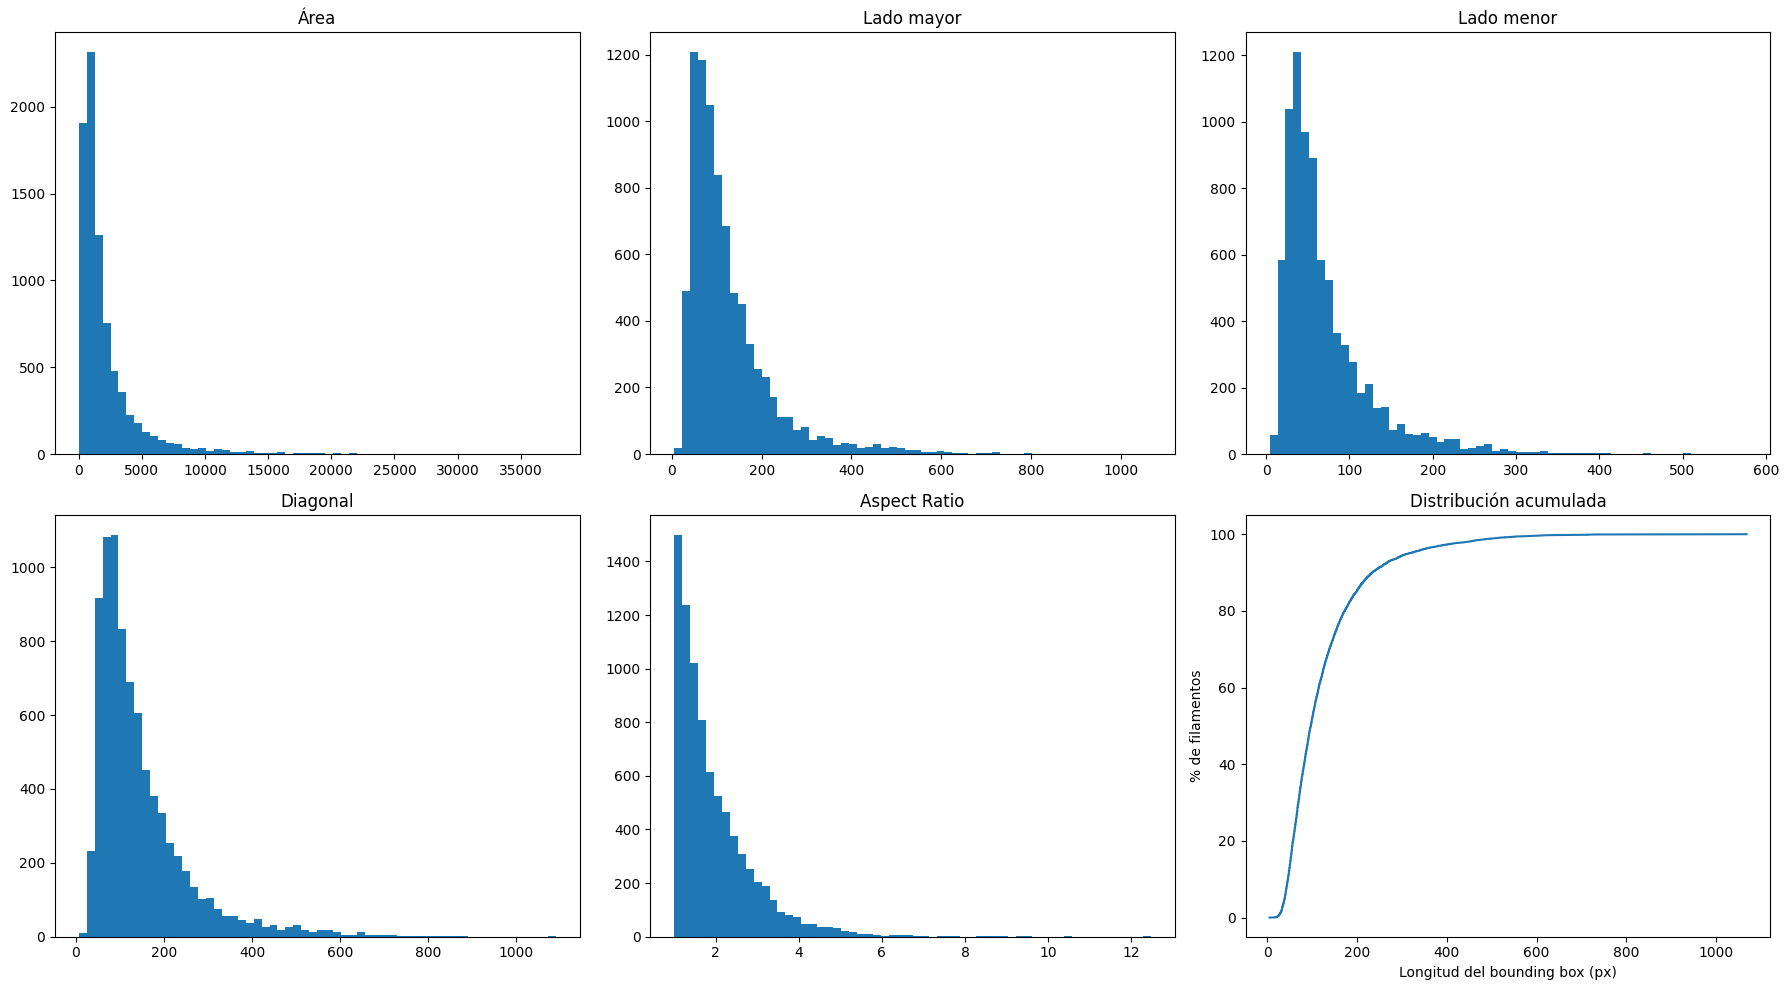

In [ ]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# CONFIGURACIÓN
# =====================================================

RUTA_JSON = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"

# =====================================================
# CARGAR JSON
# =====================================================

with open(RUTA_JSON, "r", encoding="utf-8") as f:
    data = json.load(f)

print(f"Imágenes: {len(data['images'])}")
print(f"Anotaciones: {len(data['annotations'])}")

# =====================================================
# LISTAS DE MEDIDAS
# =====================================================

areas = []
largos = []
anchos = []
diagonales = []
aspect_ratios = []

# =====================================================
# RECORRER TODOS LOS FILAMENTOS
# =====================================================

for ann in data["annotations"]:

    if "segmentation" not in ann:
        continue

    for seg in ann["segmentation"]:

        pts = np.array(seg, dtype=np.float32).reshape((-1, 2))

        # Área del polígono
        area = cv2.contourArea(pts)

        # Bounding box
        x, y, w, h = cv2.boundingRect(pts.astype(np.int32))

        largo = max(w, h)
        ancho = min(w, h)
        diagonal = np.sqrt(w**2 + h**2)
        aspect = largo / max(ancho, 1)

        areas.append(area)
        largos.append(largo)
        anchos.append(ancho)
        diagonales.append(diagonal)
        aspect_ratios.append(aspect)

areas = np.array(areas)
largos = np.array(largos)
anchos = np.array(anchos)
diagonales = np.array(diagonales)
aspect_ratios = np.array(aspect_ratios)

# =====================================================
# ESTADÍSTICAS
# =====================================================

def imprimir(nombre, valores):

    print(f"\n========== {nombre} ==========")
    print(f"Media     : {np.mean(valores):.2f}")
    print(f"Mediana   : {np.median(valores):.2f}")
    print(f"Mínimo    : {np.min(valores):.2f}")
    print(f"Máximo    : {np.max(valores):.2f}")

    for p in [50, 75, 90, 95, 99]:
        print(f"P{p:<2}      : {np.percentile(valores,p):.2f}")

print(f"\nNúmero total de filamentos: {len(areas)}")

imprimir("Área (px²)", areas)
imprimir("Lado mayor Bounding Box (px)", largos)
imprimir("Lado menor Bounding Box (px)", anchos)
imprimir("Diagonal Bounding Box (px)", diagonales)
imprimir("Aspect Ratio", aspect_ratios)

# =====================================================
# HISTOGRAMAS
# =====================================================

fig, axs = plt.subplots(2,3, figsize=(18,10))

axs[0,0].hist(areas, bins=60)
axs[0,0].set_title("Área")

axs[0,1].hist(largos, bins=60)
axs[0,1].set_title("Lado mayor")

axs[0,2].hist(anchos, bins=60)
axs[0,2].set_title("Lado menor")

axs[1,0].hist(diagonales, bins=60)
axs[1,0].set_title("Diagonal")

axs[1,1].hist(aspect_ratios, bins=60)
axs[1,1].set_title("Aspect Ratio")

# Último gráfico: distribución acumulada del largo

largos_ordenados = np.sort(largos)
porcentaje = np.arange(len(largos_ordenados)) / len(largos_ordenados) * 100

axs[1,2].plot(largos_ordenados, porcentaje)
axs[1,2].set_xlabel("Longitud del bounding box (px)")
axs[1,2].set_ylabel("% de filamentos")
axs[1,2].set_title("Distribución acumulada")

plt.tight_layout()
plt.show()

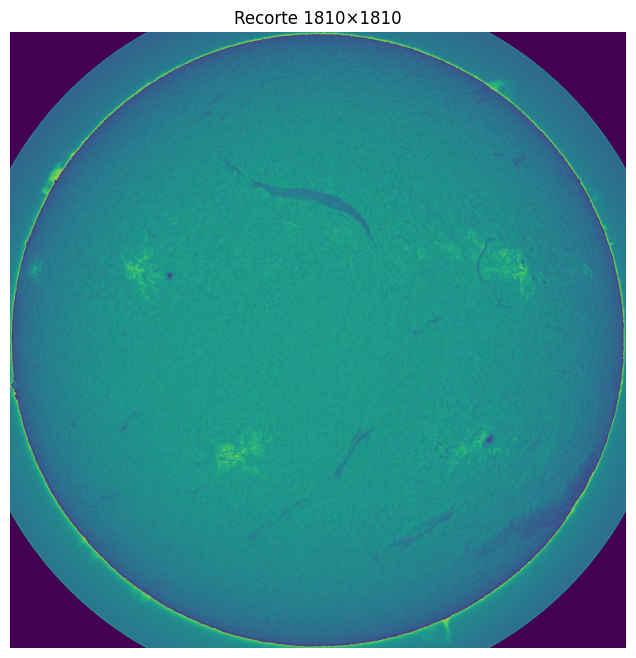

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt


def recortar_centro(imagen, ancho_recorte, alto_recorte):
    ancho, alto = imagen.size

    if ancho_recorte > ancho or alto_recorte > alto:
        raise ValueError("El recorte es mayor que la imagen.")

    izquierda = (ancho - ancho_recorte) // 2
    superior = (alto - alto_recorte) // 2
    derecha = izquierda + ancho_recorte
    inferior = superior + alto_recorte

    return imagen.crop((izquierda, superior, derecha, inferior))


# Cargar imagen
imagen = Image.open("/content/20220714185352Th.jpeg")

# Tamaño del recorte
ancho_recorte = 1810
alto_recorte = 1810

# Recortar
recorte = recortar_centro(imagen, ancho_recorte, alto_recorte)

# Mostrar en Colab
plt.figure(figsize=(8, 8))
plt.imshow(recorte)
plt.axis("off")
plt.title(f"Recorte {ancho_recorte}×{alto_recorte}")
plt.show()

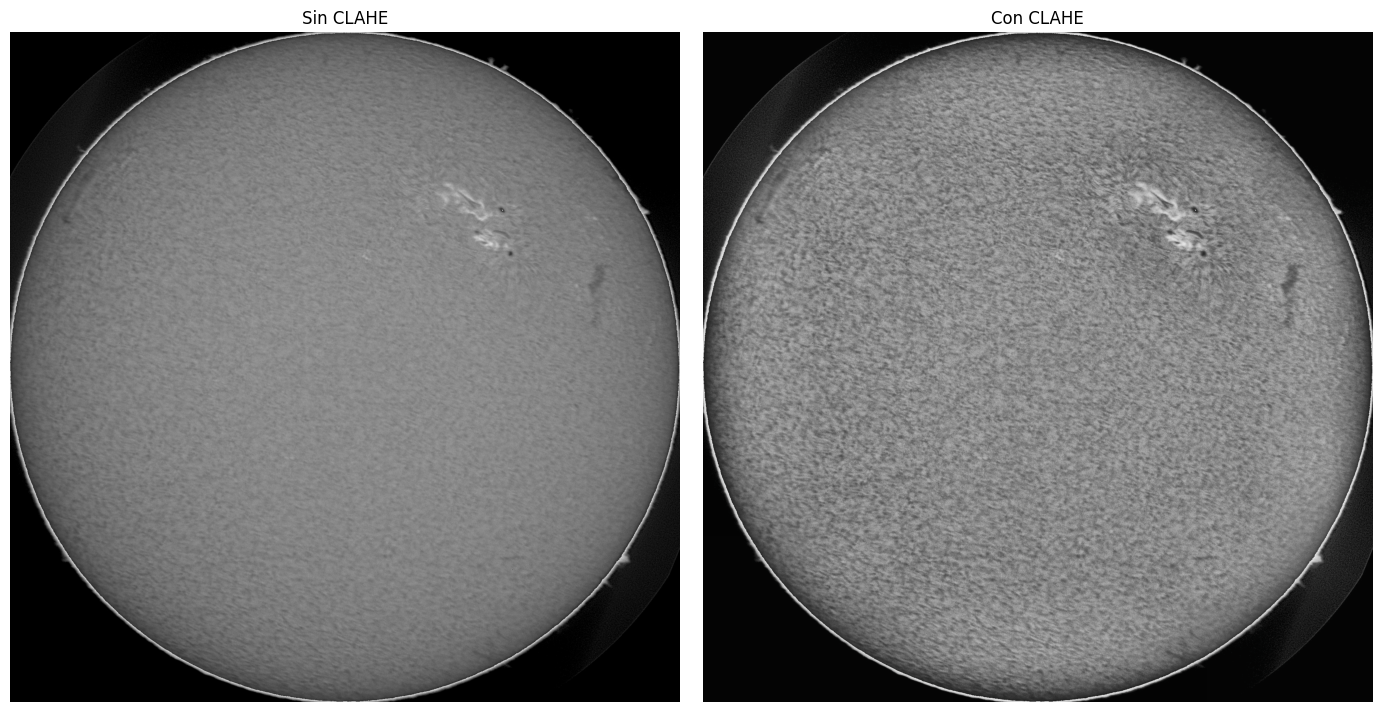

In [ ]:
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt


def recortar_centro(imagen, ancho_recorte, alto_recorte):
    ancho, alto = imagen.size

    izquierda = (ancho - ancho_recorte) // 2
    superior = (alto - alto_recorte) // 2
    derecha = izquierda + ancho_recorte
    inferior = superior + alto_recorte

    return imagen.crop((izquierda, superior, derecha, inferior))


# ------------------------
# Configuración
# ------------------------
imagen = Image.open("/content/20110123174914Mh.jpeg")

ancho_recorte = 1800
alto_recorte = 1800

# ------------------------
# Recorte
# ------------------------
recorte = recortar_centro(imagen, ancho_recorte, alto_recorte)

# Convertir a OpenCV (BGR)
img_cv = cv2.cvtColor(np.array(recorte), cv2.COLOR_RGB2BGR)

# ------------------------
# CLAHE
# ------------------------
lab = cv2.cvtColor(img_cv, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
l_clahe = clahe.apply(l)

lab_clahe = cv2.merge((l_clahe, a, b))
img_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)

# Imagen original (sin CLAHE)
img_original = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)

# ------------------------
# Mostrar resultados
# ------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

ax[0].imshow(img_original)
ax[0].set_title("Sin CLAHE")
ax[0].axis("off")

ax[1].imshow(img_clahe)
ax[1].set_title("Con CLAHE")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# CONFIGURACIÓN DE RUTAS
# =====================================================================
RUTA_JSON = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
CARPETA_IMAGENES = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images"
CARPETA_SALIDA = "/content/resultados_analisis_color"   # Carpeta para guardar los gráficos

def analizar_color_filamentos():
    if not os.path.exists(RUTA_JSON):
        print(f"❌ Error: No se encuentra el archivo JSON en '{RUTA_JSON}'")
        return

    os.makedirs(CARPETA_SALIDA, exist_ok=True)

    print("⏳ Cargando archivo JSON...")
    with open(RUTA_JSON, 'r', encoding='utf-8') as f:
        data = json.load(f)
    print("✅ JSON cargado.")

    images_dict = {img['id']: img for img in data.get('images', [])}

    # Listas globales para acumular los píxeles de TODOS los filamentos del dataset
    todos_los_pixeles_b = []
    todos_los_pixeles_g = []
    todos_los_pixeles_r = []

    print("📦 Agrupando anotaciones...")
    annotations_por_imagen = {}
    for ann in data.get('annotations', []):
        img_id = ann['image_id']
        annotations_por_imagen.setdefault(img_id, []).append(ann)

    total_imagenes = len(annotations_por_imagen)
    print(f"📌 Procesando filamentos en {total_imagenes} imágenes para analizar color...")
    print("-" * 70)

    for i, (img_id, lista_anotaciones) in enumerate(annotations_por_imagen.items(), 1):
        if img_id not in images_dict:
            continue

        img_info = images_dict[img_id]
        nombre_archivo = img_info['file_name']
        ruta_imagen_local = os.path.join(CARPETA_IMAGENES, nombre_archivo)

        if not os.path.exists(ruta_imagen_local):
            continue

        img = cv2.imread(ruta_imagen_local)
        if img is None:
            continue

        # Crear una máscara en negro del mismo tamaño que la imagen (un solo canal)
        mascara_acumulada = np.zeros(img.shape[:2], dtype=np.uint8)
        hay_poligonos = False

        for ann in lista_anotaciones:
            if 'segmentation' in ann and ann['segmentation']:
                hay_poligonos = True
                for seg in ann['segmentation']:
                    # Reorganizar los puntos del polígono
                    pts = np.array(seg, dtype=np.int32).reshape((-1, 1, 2))
                    # Pintar el interior del polígono de blanco (255) en la máscara
                    cv2.fillPoly(mascara_acumulada, [pts], 255)

        # Si la imagen tenía polígonos válidos, extraemos sus colores
        if hay_poligonos:
            # Extraemos los píxeles de la imagen original usando la máscara
            pixeles_dentro = img[mascara_acumulada == 255]

            if len(pixeles_dentro) > 0:
                # OpenCV lee en BGR, separamos los canales
                todos_los_pixeles_b.extend(pixeles_dentro[:, 0])
                todos_los_pixeles_g.extend(pixeles_dentro[:, 1])
                todos_los_pixeles_r.extend(pixeles_dentro[:, 2])

        if i % 50 == 0:
            print(f"📸 Analizadas {i}/{total_imagenes} imágenes...")

    # =====================================================================
    # CÁLCULO DE ESTADÍSTICAS Y GENERACIÓN DE GRÁFICOS GLOBAL
    # =====================================================================
    if len(todos_los_pixeles_b) == 0:
        print("❌ No se encontraron píxeles dentro de ningún polígono. Revisa tus datos.")
        return

    # Convertir a arrays de numpy para cálculos rápidos
    b_array = np.array(todos_los_pixeles_b)
    g_array = np.array(todos_los_pixeles_g)
    r_array = np.array(todos_los_pixeles_r)

    print("-" * 70)
    print("📊 ¡ANÁLISIS ESTADÍSTICO DETALLADO DEL COLOR (Escala 0-255)!")
    print("-" * 70)

    # Canal Rojo (R)
    print(f"🔴 CANAL ROJO (R):")
    print(f"   • Mínimo: {np.min(r_array)}")
    print(f"   • Máximo: {np.max(r_array)}")
    print(f"   • Media:  {np.mean(r_array):.2f}")
    print(f"   • Mediana: {np.median(r_array):.2f}")
    print(f"   • Desv. Estándar: {np.std(r_array):.2f}\n")

    # Canal Verde (G)
    print(f"🟢 CANAL VERDE (G):")
    print(f"   • Mínimo: {np.min(g_array)}")
    print(f"   • Máximo: {np.max(g_array)}")
    print(f"   • Media:  {np.mean(g_array):.2f}")
    print(f"   • Mediana: {np.median(g_array):.2f}")
    print(f"   • Desv. Estándar: {np.std(g_array):.2f}\n")

    # Canal Azul (B)
    print(f"🔵 CANAL AZUL (B):")
    print(f"   • Mínimo: {np.min(b_array)}")
    print(f"   • Máximo: {np.max(b_array)}")
    print(f"   • Media:  {np.mean(b_array):.2f}")
    print(f"   • Mediana: {np.median(b_array):.2f}")
    print(f"   • Desv. Estándar: {np.std(b_array):.2f}")
    print("-" * 70)

    # Dibujar el histograma de distribución
    plt.figure(figsize=(10, 6))

    # Calculamos histogramas para los 3 canales
    plt.hist(r_array, bins=256, range=(0, 256), color='red', alpha=0.6, label='Rojo (R)')
    plt.hist(g_array, bins=256, range=(0, 256), color='green', alpha=0.6, label='Verde (G)')
    plt.hist(b_array, bins=256, range=(0, 256), color='blue', alpha=0.6, label='Azul (B)')

    plt.title('Distribución Global del Tono de Color dentro de los Filamentos')
    plt.xlabel('Intensidad del Píxel (0 - 255)')
    plt.ylabel('Cantidad de Píxeles (Frecuencia)')
    plt.legend(loc='upper right')
    plt.grid(axis='y', alpha=0.3)

    # Guardar gráfico resultante
    ruta_grafico = os.path.join(CARPETA_SALIDA, "distribucion_color_filamentos.png")
    plt.savefig(ruta_grafico, bbox_inches='tight')
    plt.close()

    print(f"🎉 ¡Análisis finalizado con éxito!")
    print(f"📊 Gráfico guardado en: '{ruta_grafico}'")

if __name__ == "__main__":
    analizar_color_filamentos()

⏳ Cargando archivo JSON...
✅ JSON cargado.
📦 Agrupando anotaciones...
📌 Procesando filamentos en 1154 imágenes para analizar color...
----------------------------------------------------------------------
📸 Analizadas 50/1154 imágenes...
📸 Analizadas 100/1154 imágenes...
📸 Analizadas 150/1154 imágenes...
📸 Analizadas 200/1154 imágenes...
📸 Analizadas 250/1154 imágenes...
📸 Analizadas 300/1154 imágenes...
📸 Analizadas 350/1154 imágenes...
📸 Analizadas 400/1154 imágenes...
📸 Analizadas 450/1154 imágenes...
📸 Analizadas 500/1154 imágenes...
📸 Analizadas 550/1154 imágenes...
📸 Analizadas 600/1154 imágenes...
📸 Analizadas 650/1154 imágenes...
📸 Analizadas 700/1154 imágenes...
📸 Analizadas 750/1154 imágenes...
📸 Analizadas 800/1154 imágenes...
📸 Analizadas 850/1154 imágenes...
📸 Analizadas 900/1154 imágenes...
📸 Analizadas 950/1154 imágenes...
📸 Analizadas 1000/1154 imágenes...
📸 Analizadas 1050/1154 imágenes...
📸 Analizadas 1100/1154 imágenes...
📸 Analizadas 1150/1154 imágenes...
----------

z-score

In [ ]:
import os
import cv2
import numpy as np

# =====================================================================
# CONFIGURACIÓN DE RUTAS
# =====================================================================
CARPETA_IMAGENES = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images"
CARPETA_SALIDA_PREPROC = "/content/train_images_aplanadas"

# =====================================================================
# PARÁMETROS DE PROCESAMIENTO
# =====================================================================
TAMANO_RECORTE = 1810

def calcular_kernel_dinamico(tamano_imagen, porcentaje=0.08):
    """
    Calcula dinámicamente un tamaño de kernel impar basado en el tamaño de la imagen.
    Por defecto usa un 8% del tamaño para un desenfoque masivo.
    """
    kernel_estimado = int(tamano_imagen * porcentaje)

    # Asegurar que sea impar: si es par, le sumamos 1.
    if kernel_estimado % 2 == 0:
        kernel_estimado += 1

    # Garantizar un tamaño mínimo por seguridad
    return max(3, kernel_estimado)

def preprocesar_soles_limbo():
    if not os.path.exists(CARPETA_IMAGENES):
        print(f"❌ Error: No se encuentra la carpeta en '{CARPETA_IMAGENES}'")
        return

    os.makedirs(CARPETA_SALIDA_PREPROC, exist_ok=True)

    archivos = [f for f in os.listdir(CARPETA_IMAGENES) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff'))]
    total_fotos = len(archivos)

    # --- CÁLCULO DINÁMICO DEL KERNEL ---
    # Para 1810px, un 8% generará un kernel de 145x145 px
    KERNEL_GAUSSIANO = calcular_kernel_dinamico(TAMANO_RECORTE, porcentaje=0.08)

    print(f"🌞 Procesando {total_fotos} imágenes...")
    print(f"⚙️  Tamaño de recorte: {TAMANO_RECORTE}x{TAMANO_RECORTE} px")
    print(f"🧪 Kernel Gaussiano calculado dinámicamente: {KERNEL_GAUSSIANO}x{KERNEL_GAUSSIANO}")
    print("-" * 70)

    # 1. Crear la máscara circular fija
    centro = TAMANO_RECORTE // 2
    radio = TAMANO_RECORTE // 2
    mascara_circular = np.zeros((TAMANO_RECORTE, TAMANO_RECORTE), dtype=np.uint8)
    cv2.circle(mascara_circular, (centro, center_y := centro), radio, 255, thickness=-1)

    contador_exito = 0

    for idx, nombre_archivo in enumerate(archivos, 1):
        ruta_input = os.path.join(CARPETA_IMAGENES, nombre_archivo)

        img = cv2.imread(ruta_input, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue

        # 2. Recortar centrado a TAMANO_RECORTE
        h, w = img.shape
        if h != TAMANO_RECORTE or w != TAMANO_RECORTE:
            start_x = max(0, (w - TAMANO_RECORTE) // 2)
            start_y = max(0, (h - TAMANO_RECORTE) // 2)
            img_recortada = img[start_y:start_y+TAMANO_RECORTE, start_x:start_x+TAMANO_RECORTE]

            if img_recortada.shape[0] != TAMANO_RECORTE or img_recortada.shape[1] != TAMANO_RECORTE:
                img_recortada = cv2.resize(img, (TAMANO_RECORTE, TAMANO_RECORTE))
        else:
            img_recortada = img

        img_float = img_recortada.astype(np.float32)

        # 🔥 TRUCO ANTI-SANGRADO: Rellenar el espacio exterior con la media del Sol
        # antes de desenfocar para que los bordes no absorban el color negro (0).
        pixeles_sol_orig = img_float[mascara_circular == 255]
        media_sol_orig = np.mean(pixeles_sol_orig) if len(pixeles_sol_orig) > 0 else 128.0

        img_para_blur = img_float.copy()
        img_para_blur[mascara_circular == 0] = media_sol_orig

        # 3. Desenfoque Gaussiano con el kernel dinámico y bordes replicados
        fondo_borroso = cv2.GaussianBlur(img_para_blur, (KERNEL_GAUSSIANO, KERNEL_GAUSSIANO), 0, borderType=cv2.BORDER_REPLICATE)

        # 4. Recomponer el fondo corregido (Solo nos interesa la zona del Sol)
        fondo_corregido = np.ones_like(img_float)
        fondo_corregido[mascara_circular == 255] = fondo_borroso[mascara_circular == 255]

        # Seguridad contra divisiones por cero o valores absurdamente bajos
        fondo_corregido[fondo_corregido < 1.0] = 1.0

        # 5. Aplanamiento por división de fondo (Elimina el oscurecimiento del limbo)
        img_aplanada = img_float / fondo_corregido

        # 6. Calcular Z-Score sobre la zona del Sol únicamente
        pixeles_sol = img_aplanada[mascara_circular == 255]
        media_sol = np.mean(pixeles_sol)
        desv_sol = np.std(pixeles_sol)

        if desv_sol == 0:
            desv_sol = 1.0

        img_zscore = (img_aplanada - media_sol) / desv_sol

        # Forzar el espacio exterior a un valor bajo constante
        img_zscore[mascara_circular == 0] = -3.0

        # 7. Normalizar a 8 bits (0-255) SOLO para poder guardar y visualizar la imagen
        min_val = np.min(img_zscore)
        max_val = np.max(img_zscore)
        if max_val - min_val == 0:
            img_final = np.zeros(img_zscore.shape, dtype=np.uint8)
        else:
            img_final = (((img_zscore - min_val) / (max_val - min_val)) * 255).astype(np.uint8)

        # Guardar resultado visual
        ruta_output = os.path.join(CARPETA_SALIDA_PREPROC, nombre_archivo)
        cv2.imwrite(ruta_output, img_final)

        contador_exito += 1
        if contador_exito % 50 == 0 or contador_exito == total_fotos:
            print(f"📸 Progreso: {contador_exito}/{total_fotos} imágenes procesadas.")

    print("-" * 70)
    print(f"🎉 ¡Proceso completado con éxito! Revisa la carpeta: {CARPETA_SALIDA_PREPROC}")

if __name__ == "__main__":
    preprocesar_soles_limbo()

🌞 Procesando 707 imágenes...
⚙️  Tamaño de recorte: 1810x1810 px
🧪 Kernel Gaussiano calculado dinámicamente: 145x145
----------------------------------------------------------------------
📸 Progreso: 50/707 imágenes procesadas.
📸 Progreso: 100/707 imágenes procesadas.
📸 Progreso: 150/707 imágenes procesadas.
📸 Progreso: 200/707 imágenes procesadas.
📸 Progreso: 250/707 imágenes procesadas.
📸 Progreso: 300/707 imágenes procesadas.
📸 Progreso: 350/707 imágenes procesadas.
📸 Progreso: 400/707 imágenes procesadas.
📸 Progreso: 450/707 imágenes procesadas.
📸 Progreso: 500/707 imágenes procesadas.
📸 Progreso: 550/707 imágenes procesadas.
📸 Progreso: 600/707 imágenes procesadas.
📸 Progreso: 650/707 imágenes procesadas.
📸 Progreso: 700/707 imágenes procesadas.
📸 Progreso: 707/707 imágenes procesadas.
----------------------------------------------------------------------
🎉 ¡Proceso completado con éxito! Revisa la carpeta: /content/train_images_aplanadas


In [ ]:
import json
import cv2
import numpy as np

def analizar_distribucion_filamentos(json_path):
    print(f"Cargando datos de: {json_path}...")

    # 1. Cargar el JSON (Formato COCO)
    with open(json_path, 'r') as f:
        data = json.load(f)

    # 2. Agrupar las anotaciones por el ID de la imagen para facilitar el acceso
    anotaciones_por_imagen = {}
    if "annotations" in data:
        for ann in data["annotations"]:
            img_id = ann["image_id"]
            if img_id not in anotaciones_por_imagen:
                anotaciones_por_imagen[img_id] = []
            anotaciones_por_imagen[img_id].append(ann)
    else:
        print("Error: No se encontró la sección 'annotations' en el JSON.")
        return

    # Listas para almacenar las estadísticas extraídas de TODOS los filamentos
    todas_areas = []
    todos_anchos = []
    todos_altos = []

    # 3. Iterar sobre todas las imágenes definidas en el JSON
    for img_info in data.get("images", []):
        img_id = img_info["id"]
        width = img_info["width"]
        height = img_info["height"]

        # Crear un "lienzo" o máscara binaria negra con las dimensiones de la imagen
        mask = np.zeros((height, width), dtype=np.uint8)

        # 4. Si la imagen tiene anotaciones, dibujamos los filamentos en el lienzo
        if img_id in anotaciones_por_imagen:
            for ann in anotaciones_por_imagen[img_id]:
                # Se asume formato COCO estándar de segmentación: [[x1, y1, x2, y2...]]
                if "segmentation" in ann and not isinstance(ann["segmentation"], dict):
                    for segmento in ann["segmentation"]:
                        # Transformar la lista plana en coordenadas (N, 1, 2)
                        pts = np.array(segmento, np.int32).reshape((-1, 1, 2))

                        # Rellenar el polígono de color blanco (255)
                        cv2.fillPoly(mask, [pts], 255)

        # 5. Aplicar connectedComponentsWithStats sobre la máscara generada
        # stats contiene [x, y, ancho, alto, área]
        num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)

        # 6. Extraer y acumular la información
        # Saltamos el índice 0 porque SIEMPRE representa el fondo (background) de la imagen
        for i in range(1, num_labels):
            todas_areas.append(stats[i, cv2.CC_STAT_AREA])
            todos_anchos.append(stats[i, cv2.CC_STAT_WIDTH])
            todos_altos.append(stats[i, cv2.CC_STAT_HEIGHT])

    # 7. Calcular y mostrar la distribución general para filtrar luego en C++
    if len(todas_areas) > 0:
        print(f"\n--- ANÁLISIS COMPLETADO: Se detectaron {len(todas_areas)} filamentos únicos en total ---")

        def imprimir_estadisticas(nombre_metrica, datos):
            print(f"\n>> Distribución de {nombre_metrica}:")
            print(f"   Min     (Filtro <):   {np.min(datos)}")
            print(f"   Max     (Filtro >):   {np.max(datos)}")
            print(f"   Mediana (P50):        {np.median(datos)}")
            print(f"   Media:                {np.mean(datos):.2f}")
            print(f"   Percentil 10 (P10):   {np.percentile(datos, 10):.2f} (El 10% mide menos que esto)")
            print(f"   Percentil 90 (P90):   {np.percentile(datos, 90):.2f} (El 90% mide menos que esto)")

        imprimir_estadisticas("Área (Píxeles totales)", todas_areas)
        imprimir_estadisticas("Ancho (Bounding Box Width)", todos_anchos)
        imprimir_estadisticas("Alto (Bounding Box Height)", todos_altos)

    else:
        print("\nNo se encontraron filamentos válidos para analizar.")

# ==========================================
# Ejecución del Script
# ==========================================
if __name__ == "__main__":
    # Sustituye esto por la ruta real a tu archivo JSON de anotaciones
    RUTA_JSON = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    analizar_distribucion_filamentos(RUTA_JSON)

Cargando datos de: /content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json...

--- ANÁLISIS COMPLETADO: Se detectaron 8184 filamentos únicos en total ---

>> Distribución de Área (Píxeles totales):
   Min     (Filtro <):   101
   Max     (Filtro >):   39122
   Mediana (P50):        1367.5
   Media:                2297.25
   Percentil 10 (P10):   474.00 (El 10% mide menos que esto)
   Percentil 90 (P90):   5037.50 (El 90% mide menos que esto)

>> Distribución de Ancho (Bounding Box Width):
   Min     (Filtro <):   9
   Max     (Filtro >):   1068
   Mediana (P50):        76.0
   Media:                104.34
   Percentil 10 (P10):   32.00 (El 10% mide menos que esto)
   Percentil 90 (P90):   204.00 (El 90% mide menos que esto)

>> Distribución de Alto (Bounding Box Height):
   Min     (Filtro <):   8
   Max     (Filtro >):   711
   Mediana (P50):        71.0
   Media:                92.83
   Percentil 10 (P10):   30.00 (El 10% mide m

In [ ]:
import json

def contar_fotos_con_filamentos(json_path):
    try:
        with open(json_path, 'r') as f:
            data = json.load(f)

        # Accedemos a la lista de anotaciones
        anotaciones = data.get('annotations', [])

        # Usamos un set para obtener solo los ID únicos de las imágenes
        # que aparecen en las anotaciones (esto elimina duplicados automáticamente)
        fotos_con_filamentos = {ann['image_id'] for ann in anotaciones}

        return len(fotos_con_filamentos)

    except FileNotFoundError:
        return "Error: No se encontró el archivo JSON."
    except KeyError:
        return "Error: El formato del JSON no parece ser el estándar esperado."

# --- Uso del script ---
ruta_json = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"  # Cambia esto por la ruta de tu archivo
total_fotos = contar_fotos_con_filamentos(ruta_json)

print(f"Total de imágenes que contienen al menos un filamento: {total_fotos}")

Total de imágenes que contienen al menos un filamento: 1154


In [ ]:
import json
import requests
import os

def descargar_imagenes_dataset(json_path, carpeta_destino):
    # 1. Crear la carpeta si no existe
    if not os.path.exists(carpeta_destino):
        os.makedirs(carpeta_destino)
        print(f"Carpeta '{carpeta_destino}' creada.")

    # 2. Cargar el JSON
    with open(json_path, 'r') as f:
        data = json.load(f)

    imagenes = data.get("images", [])
    total = len(imagenes)

    print(f"Iniciando descarga de {total} imágenes...")

    # 3. Descargar cada imagen
    for i, img in enumerate(imagenes):
        url = img.get("url")
        nombre_archivo = img.get("file_name", f"imagen_{i}.jpg")
        ruta_guardado = os.path.join(carpeta_destino, nombre_archivo)

        try:
            print(f"[{i+1}/{total}] Descargando: {nombre_archivo}...")
            response = requests.get(url, stream=True, timeout=10)

            # Verificar si la petición fue exitosa
            if response.status_code == 200:
                with open(ruta_guardado, 'wb') as f:
                    for chunk in response.iter_content(1024):
                        f.write(chunk)
            else:
                print(f"   Error: No se pudo descargar {url} (Status: {response.status_code})")

        except Exception as e:
            print(f"   Error al conectar con {url}: {e}")

    print("\n¡Proceso de descarga finalizado!")

# --- Configuración ---
# Asegúrate de poner el nombre correcto de tu archivo JSON
ARCHIVO_JSON = "/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
CARPETA = "/content/fotos nuevas"

descargar_imagenes_dataset(ARCHIVO_JSON, CARPETA)

In [ ]:
import json
import numpy as np
import cv2

# Ruta de tu archivo JSON
json_path = '/content/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json'

with open(json_path, 'r') as f:
    coco_data = json.load(f)

areas = []
mask = np.zeros((2048, 2048), dtype=np.uint8)

for ann in coco_data.get('annotations', []):
    segmentation = ann.get('segmentation', [])
    if segmentation:
        mask.fill(0)
        polygons = [np.array(poly, dtype=np.int32).reshape((-1, 1, 2)) for poly in segmentation]
        cv2.fillPoly(mask, polygons, 255)
        area = cv2.countNonZero(mask)
        if area > 0:
            areas.append(area)

areas = np.array(areas)

# --- ANÁLISIS AVANZADO ---
def print_separator(title):
    print(f"\n{'='*60}\n {title} \n{'='*60}")

print_separator("📊 ESTADÍSTICAS GRANULARES DE TAMAÑO")
print(f"Total de filamentos: {len(areas)}")
print(f"Media (promedio)   : {np.mean(areas):.2f}")
print(f"Desviación Estándar: {np.std(areas):.2f} (indica qué tan variados son los tamaños)")
print(f"Mediana (50%)      : {np.median(areas)}")

print_separator("📉 PERCENTILES CLAVE (Distribución)")
percentiles = [0.1, 0.5, 1, 2, 5, 10, 25, 50, 75, 90, 95, 99]
for p in percentiles:
    val = np.percentile(areas, p)
    print(f"Percentil {p:4}%: {int(val)} píxeles (Debajo de este valor está el {p}% más pequeño)")

print_separator("🔍 IMPACTO DEL FILTRO (¿Cuántos perderías?)")
# Definimos umbrales de prueba
thresholds = [10, 20, 50, 100, 150, 200, 250, 300, 500]
print(f"{'Umbral (px)':<15} | {'Filamentos eliminados':<20} | {'% del total perdido'}")
print("-" * 60)
for t in thresholds:
    lost = np.sum(areas < t)
    percentage = (lost / len(areas)) * 100
    print(f"{t:<15} | {lost:<20} | {percentage:.2f}%")


 📊 ESTADÍSTICAS GRANULARES DE TAMAÑO 
Total de filamentos: 8199
Media (promedio)   : 2293.71
Desviación Estándar: 2858.19 (indica qué tan variados son los tamaños)
Mediana (50%)      : 1365.0

 📉 PERCENTILES CLAVE (Distribución) 
Percentil  0.1%: 132 píxeles (Debajo de este valor está el 0.1% más pequeño)
Percentil  0.5%: 212 píxeles (Debajo de este valor está el 0.5% más pequeño)
Percentil    1%: 254 píxeles (Debajo de este valor está el 1% más pequeño)
Percentil    2%: 292 píxeles (Debajo de este valor está el 2% más pequeño)
Percentil    5%: 367 píxeles (Debajo de este valor está el 5% más pequeño)
Percentil   10%: 473 píxeles (Debajo de este valor está el 10% más pequeño)
Percentil   25%: 757 píxeles (Debajo de este valor está el 25% más pequeño)
Percentil   50%: 1365 píxeles (Debajo de este valor está el 50% más pequeño)
Percentil   75%: 2648 píxeles (Debajo de este valor está el 75% más pequeño)
Percentil   90%: 5034 píxeles (Debajo de este valor está el 90% más pequeño)
Percent